In [1]:

import sys
from pathlib import Path
import numpy as np
import pandas as pd

# Locate project root
ROOT = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)

sys.path.insert(0, str(ROOT / "src"))

from data_loader import load_data, relevant_items_val
from semantic_based import SemanticEmbeddingRecommender

# Load the same experiment data as TF-IDF
train, val, cand_set, seen = load_data(
    str(ROOT / "data") + "/"
)

# Apply the same relevance definition
relevant = relevant_items_val(
    val,
    cand_set,
    seen,
    min_rating=4,
)

K = 10

print("=== SEMANTIC EXPERIMENT DATA ===")
print(f"Training interactions: {len(train):,}")
print(f"Validation interactions: {len(val):,}")
print(f"Warm candidates: {len(cand_set):,}")
print(f"Seen users: {len(seen):,}")
print(f"Evaluable users: {len(relevant):,}")
print(f"Recommendation K: {K}")

=== SEMANTIC EXPERIMENT DATA ===
Training interactions: 427,957
Validation interactions: 41,284
Warm candidates: 22,753
Seen users: 54,483
Evaluable users: 11,850
Recommendation K: 10


In [2]:

# Fit Semantic Embedding Recommender

model = SemanticEmbeddingRecommender(
    min_rating=4
).fit(
    train,
    cand_set
)

print("=== SEMANTIC MODEL FIT ===")
print("Candidate items:", len(model.candidate_items))
print("Items with embeddings:", len(model.item_index))
print("Users with positive profiles:", len(model.user_items))
print("Embedding dimension:", model.item_matrix.shape[1])
print("Fit completed successfully.")


=== SEMANTIC MODEL FIT ===
Candidate items: 22753
Items with embeddings: 22753
Users with positive profiles: 54036
Embedding dimension: 384
Fit completed successfully.


In [3]:

def evaluate_semantic_at_k(model, relevant, seen, cand_set, k=10):
    recalls = []
    ndcgs = []
    hit_rates = []

    rec_rows = []

    violations = {
        "wrong_length": 0,
        "duplicate_items": 0,
        "seen_items": 0,
        "non_candidate_items": 0,
    }

    no_profile_users = []

    total_users = len(relevant)

    for count, (user_id, relevant_items) in enumerate(
        relevant.items(), start=1
    ):
        recs = model.recommend(user_id, seen, k=k)

        relevant_items = set(relevant_items)
        seen_items = seen.get(user_id, set())

        # Calculate evaluation metrics.
        hits = [item in relevant_items for item in recs]

        recalls.append(
            sum(hits) / len(relevant_items)
        )

        dcg = sum(
            hit / np.log2(rank + 2)
            for rank, hit in enumerate(hits)
        )

        ideal_hits = min(len(relevant_items), k)

        idcg = sum(
            1 / np.log2(rank + 2)
            for rank in range(ideal_hits)
        )

        ndcgs.append(
            dcg / idcg if idcg else 0.0
        )

        hit_rates.append(float(any(hits)))

        # Check recommendation rules.
        if len(recs) != k:
            violations["wrong_length"] += 1

        if len(set(recs)) != len(recs):
            violations["duplicate_items"] += 1

        if set(recs) & seen_items:
            violations["seen_items"] += 1

        if not set(recs).issubset(cand_set):
            violations["non_candidate_items"] += 1

        if model.user_profile(user_id) is None:
            no_profile_users.append(user_id)

        # Keep recommendations for later CSV export.
        rec_rows.extend(
            {
                "user_id": user_id,
                "item_id": item,
                "rank": rank + 1,
                "relevant": item in relevant_items,
            }
            for rank, item in enumerate(recs)
        )

        if count % 1000 == 0 or count == total_users:
            print(f"Evaluated: {count:,}/{total_users:,} users")

    metrics = {
        f"Recall@{k}": float(np.mean(recalls)),
        f"NDCG@{k}": float(np.mean(ndcgs)),
        f"HitRate@{k}": float(np.mean(hit_rates)),
        "n_eval_users": total_users,
        "n_eval_users_with_profile": (
            total_users - len(no_profile_users)
        ),
    }

    return metrics, pd.DataFrame(rec_rows), violations, no_profile_users


# Run evaluation for all validation users.
semantic_metrics, semantic_recs, rule_violations, no_profile_users = (
    evaluate_semantic_at_k(
        model,
        relevant,
        seen,
        cand_set,
        k=K,
    )
)

print("\n=== SEMANTIC EVALUATION RESULTS ===")
display(pd.Series(semantic_metrics))

print("\n=== RECOMMENDATION RULE CHECK ===")
display(pd.Series(rule_violations))

print("\nUsers without positive profiles:", len(no_profile_users))
print("Total recommendation rows:", len(semantic_recs))


Evaluated: 1,000/11,850 users
Evaluated: 2,000/11,850 users
Evaluated: 3,000/11,850 users
Evaluated: 4,000/11,850 users
Evaluated: 5,000/11,850 users
Evaluated: 6,000/11,850 users
Evaluated: 7,000/11,850 users
Evaluated: 8,000/11,850 users
Evaluated: 9,000/11,850 users
Evaluated: 10,000/11,850 users
Evaluated: 11,000/11,850 users
Evaluated: 11,850/11,850 users

=== SEMANTIC EVALUATION RESULTS ===


Recall@10                        0.008860
NDCG@10                          0.005361
HitRate@10                       0.015696
n_eval_users                 11850.000000
n_eval_users_with_profile    11659.000000
dtype: float64


=== RECOMMENDATION RULE CHECK ===


wrong_length           0
duplicate_items        0
seen_items             0
non_candidate_items    0
dtype: int64


Users without positive profiles: 191
Total recommendation rows: 118500


In [4]:

import random

# Use the same 200-user sample protocol as the TF-IDF notebook.
random.seed(42)

sanity_users = random.sample(
    sorted(relevant),
    200
)

sanity_violations = {
    "wrong_length": 0,
    "duplicate_items": 0,
    "seen_items": 0,
    "non_candidate_items": 0,
}

for user_id in sanity_users:
    recs = model.recommend(user_id, seen, k=10)

    if len(recs) != 10:
        sanity_violations["wrong_length"] += 1

    if len(set(recs)) != len(recs):
        sanity_violations["duplicate_items"] += 1

    if set(recs) & seen.get(user_id, set()):
        sanity_violations["seen_items"] += 1

    if not set(recs).issubset(cand_set):
        sanity_violations["non_candidate_items"] += 1

print("=== SEMANTIC TOP-10 SANITY CHECK ===")
print("Sample users:", len(sanity_users))

for rule, count in sanity_violations.items():
    print(f"{rule}: {count}")


=== SEMANTIC TOP-10 SANITY CHECK ===
Sample users: 200
wrong_length: 0
duplicate_items: 0
seen_items: 0
non_candidate_items: 0


In [5]:

import random

# Use the same 200-user sample protocol as the TF-IDF notebook.
random.seed(42)

sanity_users = random.sample(
    sorted(relevant),
    200
)

sanity_violations = {
    "wrong_length": 0,
    "duplicate_items": 0,
    "seen_items": 0,
    "non_candidate_items": 0,
}

for user_id in sanity_users:
    recs = model.recommend(user_id, seen, k=10)

    if len(recs) != 10:
        sanity_violations["wrong_length"] += 1

    if len(set(recs)) != len(recs):
        sanity_violations["duplicate_items"] += 1

    if set(recs) & seen.get(user_id, set()):
        sanity_violations["seen_items"] += 1

    if not set(recs).issubset(cand_set):
        sanity_violations["non_candidate_items"] += 1

print("=== SEMANTIC TOP-10 SANITY CHECK ===")
print("Sample users:", len(sanity_users))

for rule, count in sanity_violations.items():
    print(f"{rule}: {count}")


=== SEMANTIC TOP-10 SANITY CHECK ===
Sample users: 200
wrong_length: 0
duplicate_items: 0
seen_items: 0
non_candidate_items: 0


In [6]:

import json
import platform
import sys
from datetime import datetime

import sentence_transformers
import torch

# Create semantic-specific output paths.
OUT = ROOT / "outputs"

OUTPUT_FILES = {
    "configs": OUT / "configs" / "semantic_cbf.json",
    "metrics": OUT / "metrics" / "semantic_cbf_val.json",
    "recs": OUT / "recs" / "semantic_cbf_val_top10.csv",
    "logs": OUT / "logs" / "semantic_cbf_run.json",
}

for path in OUTPUT_FILES.values():
    path.parent.mkdir(parents=True, exist_ok=True)


# Calculate recommendation scores for the saved Top-10 results.
# Users without profiles receive NaN scores for popularity fallback.
saved_recs = semantic_recs.copy()

scores = np.full(len(saved_recs), np.nan)

for user_id, group in saved_recs.groupby("user_id", sort=False):
    profile = model.user_profile(user_id)

    if profile is None:
        continue

    row_indices = group.index.to_numpy()

    item_rows = group["item_id"].map(
        model.item_index
    ).to_numpy(dtype=np.int64)

    scores[row_indices] = (
        model.item_matrix[item_rows] @ profile
    )

saved_recs["score"] = scores

saved_recs = saved_recs[
    ["user_id", "item_id", "score", "rank", "relevant"]
]


# Save recommendations.
saved_recs.to_csv(
    OUTPUT_FILES["recs"],
    index=False,
)


# Create experiment configuration.
run_started = datetime.now()
run_id = "semantic_cbf_" + run_started.strftime("%Y%m%d-%H%M%S")

config = {
    "run_id": run_id,
    "model": "SemanticEmbeddingRecommender",
    "embedding_model": "sentence-transformers/all-MiniLM-L6-v2",

    "data": {
        "train": "data/interactions_train.csv",
        "validation": "data/interactions_validation.csv",
        "candidates": "data/candidate_items_warm.csv",
        "items": "data/items.csv",
        "text_column": "content_text_basic",
    },

    "embedding": {
        "dimension": 384,
        "max_seq_length": 256,
        "batch_size": 32,
        "device": "cpu",
        "n_items": len(model.item_index),
        "truncated_texts": 8276,
        "truncated_tokens": 1772380,
        "files": [
            "outputs/embeddings/item_embeddings.npy",
            "outputs/embeddings/item_ids.npy",
        ],
    },

    "recommender": {
        "min_rating": 4,
        "k": K,
        "user_profile": "Mean of positive train item embeddings, followed by L2 normalization.",
        "scoring": "Cosine similarity using normalized item embeddings and normalized user profiles.",
        "seen_items_excluded": True,
        "fallback": "Train popularity for users without a profile and remaining non-positive score slots.",
    },

    "evaluation": {
        "n_eval_users": len(relevant),
        "relevance_rule": "Validation rating >= 4, warm candidates, excluding train-seen items.",
        "metrics": list(semantic_metrics.keys())[:3],
    },
}


# Save evaluation metrics.
metrics_output = {
    **semantic_metrics,
    "sanity_check_users": len(sanity_users),
}


# Save experiment log.
log = {
    "run_id": run_id,
    "saved_at": run_started.isoformat(timespec="seconds"),
    "embedding_model": config["embedding_model"],
    "n_recommendation_rows": len(saved_recs),
    "users_without_profile": len(no_profile_users),

    "full_evaluation_rule_violations": rule_violations,
    "sanity_check_rule_violations": sanity_violations,

    "embedding_truncation": {
        "truncated_texts": 8276,
        "truncated_tokens": 1772380,
    },

    "checks": {
        "embedding_shape_valid": True,
        "embedding_ids_valid": True,
        "l2_normalization_valid": True,
        "full_evaluation_rules_passed": all(
            value == 0 for value in rule_violations.values()
        ),
        "sanity_check_passed": all(
            value == 0 for value in sanity_violations.values()
        ),
    },

    "environment": {
        "python": sys.version.split()[0],
        "platform": platform.platform(),
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "torch": torch.__version__,
        "sentence_transformers": sentence_transformers.__version__,
    },
}


# Write JSON files.
OUTPUT_FILES["configs"].write_text(
    json.dumps(config, indent=2, ensure_ascii=False) + "\n",
    encoding="utf-8",
)

OUTPUT_FILES["metrics"].write_text(
    json.dumps(metrics_output, indent=2, ensure_ascii=False) + "\n",
    encoding="utf-8",
)

OUTPUT_FILES["logs"].write_text(
    json.dumps(log, indent=2, ensure_ascii=False) + "\n",
    encoding="utf-8",
)


print("=== EXPERIMENT OUTPUTS SAVED ===")
print("Run ID:", run_id)
print("Recommendations:", len(saved_recs))

for name, path in OUTPUT_FILES.items():
    print(f"{name}: {path.relative_to(ROOT)}")

print("\nMetrics:")
display(pd.Series(semantic_metrics))

print("\nAll experiment outputs saved successfully.")


d:\TUGAS KULIAH\recsys-lexical-vs-semantic-g11\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


=== EXPERIMENT OUTPUTS SAVED ===
Run ID: semantic_cbf_20261031-110440
Recommendations: 118500
configs: outputs\configs\semantic_cbf.json
metrics: outputs\metrics\semantic_cbf_val.json
recs: outputs\recs\semantic_cbf_val_top10.csv
logs: outputs\logs\semantic_cbf_run.json

Metrics:


Recall@10                        0.008860
NDCG@10                          0.005361
HitRate@10                       0.015696
n_eval_users                 11850.000000
n_eval_users_with_profile    11659.000000
dtype: float64


All experiment outputs saved successfully.


In [7]:

import json

# Load saved metrics from both approaches.
tfidf_metrics = json.loads(
    (ROOT / "outputs/metrics/tfidf_cbf_val.json")
    .read_text(encoding="utf-8")
)

semantic_metrics_saved = json.loads(
    (ROOT / "outputs/metrics/semantic_cbf_val.json")
    .read_text(encoding="utf-8")
)

# Verify that both experiments use the same evaluation population.
assert (
    tfidf_metrics["n_eval_users"]
    == semantic_metrics_saved["n_eval_users"]
), "Evaluated user counts do not match"

assert (
    tfidf_metrics["n_eval_users_with_profile"]
    == semantic_metrics_saved["n_eval_users_with_profile"]
), "Users with profile counts do not match"

metric_names = [
    "Recall@10",
    "NDCG@10",
    "HitRate@10",
]

comparison = pd.DataFrame(
    {
        "TF-IDF CBF": [
            tfidf_metrics[m] for m in metric_names
        ],
        "Semantic CBF": [
            semantic_metrics_saved[m] for m in metric_names
        ],
    },
    index=metric_names,
)

comparison["Semantic change (%)"] = (
    (
        comparison["Semantic CBF"]
        / comparison["TF-IDF CBF"]
    ) - 1
) * 100

print("=== TF-IDF VS SEMANTIC COMPARISON ===")
print("Evaluable users:", tfidf_metrics["n_eval_users"])
print(
    "Users with positive profiles:",
    tfidf_metrics["n_eval_users_with_profile"]
)

display(
    comparison.style.format({
        "TF-IDF CBF": "{:.6f}",
        "Semantic CBF": "{:.6f}",
        "Semantic change (%)": "{:+.2f}%"
    })
)


=== TF-IDF VS SEMANTIC COMPARISON ===
Evaluable users: 11850
Users with positive profiles: 11659


,TF-IDF CBF,Semantic CBF,Semantic change (%)
Recall@10,0.012722,0.008860,-30.36%
NDCG@10,0.007452,0.005361,-28.06%
HitRate@10,0.021772,0.015696,-27.91%


Matplotlib is building the font cache; this may take a moment.


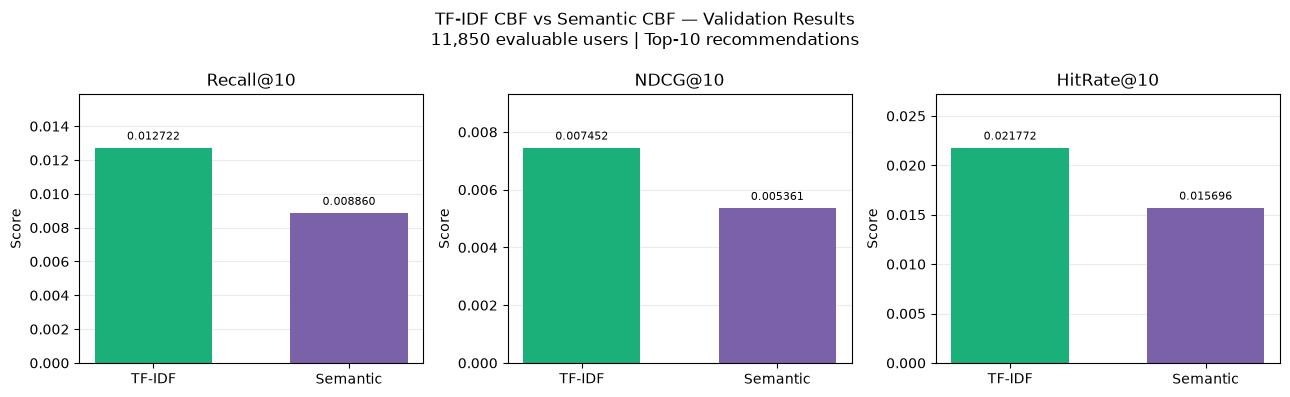

=== COMPARISON OUTPUTS ===
Figure: outputs\figures\lexical_vs_semantic_metrics.png
Metrics: outputs\metrics\lexical_vs_semantic_comparison.csv


In [9]:

import matplotlib.pyplot as plt

# Output directories
FIGURE_DIR = ROOT / "outputs" / "figures"
METRIC_DIR = ROOT / "outputs" / "metrics"

FIGURE_DIR.mkdir(parents=True, exist_ok=True)
METRIC_DIR.mkdir(parents=True, exist_ok=True)

metric_names = [
    "Recall@10",
    "NDCG@10",
    "HitRate@10",
]

# Create one chart for each metric to avoid misleading scale comparisons.
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

colors = ["#1baf7a", "#7b61a8"]

for ax, metric in zip(axes, metric_names):
    values = comparison.loc[
        metric, ["TF-IDF CBF", "Semantic CBF"]
    ]

    bars = ax.bar(
        ["TF-IDF", "Semantic"],
        values.values,
        color=colors,
        width=0.6,
    )

    ax.bar_label(
        bars,
        labels=[f"{v:.6f}" for v in values.values],
        padding=4,
        fontsize=8,
    )

    ax.set_title(metric)
    ax.set_ylabel("Score")
    ax.set_ylim(0, max(values.values) * 1.25)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

fig.suptitle(
    "TF-IDF CBF vs Semantic CBF — Validation Results\n"
    "11,850 evaluable users | Top-10 recommendations"
)

fig.tight_layout()

figure_path = FIGURE_DIR / "lexical_vs_semantic_metrics.png"
fig.savefig(figure_path, dpi=150, bbox_inches="tight")

# Save the comparison table.
comparison_path = METRIC_DIR / "lexical_vs_semantic_comparison.csv"
comparison.to_csv(comparison_path)

plt.show()

print("=== COMPARISON OUTPUTS ===")
print("Figure:", figure_path.relative_to(ROOT))
print("Metrics:", comparison_path.relative_to(ROOT))
